# 03 · Evaluación crítica de la solución (EP5 / EP6)

Este notebook respalda la sección 9 del informe: sesgos, limitaciones y robustez del hallazgo central. Trabaja sobre el catálogo integrado que genera `src/prep.py`.

Preguntas:
1. ¿Cuánto del catálogo se puede evaluar y dónde falta evidencia?
2. ¿La popularidad favorece lo reciente?
3. ¿Las películas con datos financieros representan al catálogo?
4. ¿Qué tan ruidosas son las valoraciones con pocos votos?
5. ¿El hallazgo de las joyas ocultas depende de los umbrales elegidos?
6. ¿Por qué el top 10 debe calcularse por tipo?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cat = pd.read_csv("../data/processed/catalogo_unificado.csv", low_memory=False)
print(f"{len(cat):,} contenidos · {cat.tipo.value_counts().to_dict()}")

31,991 contenidos · {'Película': 16000, 'Serie': 15991}


## 1. Cobertura de votos: dónde falta evidencia

In [2]:
conf = cat.assign(confiable=cat.valoracion_confiable.eq("Sí"))
print("% con 10 votos o más por tipo:")
print((conf.groupby("tipo").confiable.mean() * 100).round(1))
print()
print("Series: % con 10 votos o más por idioma")
print((conf[conf.tipo == "Serie"].groupby("idioma_grupo").confiable.mean() * 100).round(1).sort_values())

% con 10 votos o más por tipo:
tipo
Película    88.6
Serie       38.4
Name: confiable, dtype: float64

Series: % con 10 votos o más por idioma
idioma_grupo
Chino (mandarín)    11.0
Otros               17.2
Francés             17.8
Coreano             44.4
Español             48.1
Japonés             61.3
Inglés              63.7
Name: confiable, dtype: float64


**Lectura.** Solo el 38% de las series tiene votos suficientes, y en las series en chino la cobertura baja al 11%. Las joyas que detectamos se inclinan hacia contenido con más votos (películas, inglés, japonés). **Mitigación:** el KPI de % de valoración confiable se muestra junto a cada cifra de calidad, y se propone un plan para aumentar las valoraciones de series.

## 2. Sesgo de recencia en la popularidad

{2010: 32.3, 2011: 38.2, 2012: 41.6, 2013: 47.1, 2014: 47.6, 2015: 49.2, 2016: 53.0, 2017: 54.5, 2018: 57.3, 2019: 56.4, 2020: 42.6, 2021: 46.6, 2022: 55.9, 2023: 60.7, 2024: 69.6, 2025: 14.0}


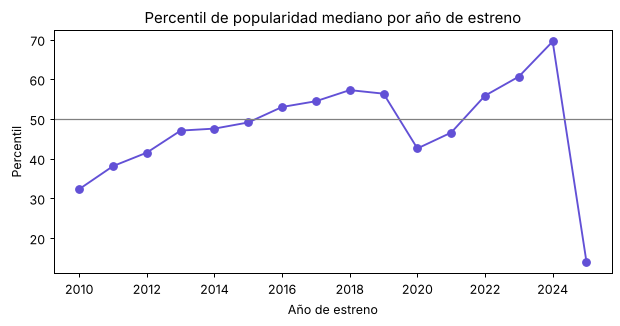

In [3]:
med = cat.groupby("anio_estreno").popularidad_percentil.median()
print(med.round(1).to_dict())
ax = med.plot(marker="o", figsize=(8, 3.5), color="#6250D6")
ax.axhline(50, color="grey", lw=1)
ax.set_title("Percentil de popularidad mediano por año de estreno")
ax.set_ylabel("Percentil"); ax.set_xlabel("Año de estreno")
plt.show()

**Lectura.** El percentil mediano sube de 32 (2010) a 70 (2024). 2025 cae a 14 porque son estrenos sin historial. Un título antiguo parece menos popular por su antigüedad. **Mitigación:** filtro de periodo visible en todas las páginas del dashboard.

## 3. Sesgo de supervivencia en finanzas

In [4]:
pel = cat[cat.tipo == "Película"]
print(pel.groupby("datos_financieros")[["popularidad_percentil", "votos"]].median())
print(f"Cobertura financiera: {(pel.datos_financieros == 'Sí').mean() * 100:.1f}% de las películas")

                   popularidad_percentil   votos
datos_financieros                               
No informados                      42.50   101.0
Sí                                 76.35  1007.0
Cobertura financiera: 22.1% de las películas


**Lectura.** Las películas con presupuesto e ingresos informados tienen percentil de popularidad mediano 76 y mediana de 1.007 votos, contra 42 y 101 sin datos. El ROI describe películas grandes y conocidas y no se generaliza al catálogo. **Mitigación:** página de Finanzas separada con la cobertura como KPI.

## 4. Ruido de las valoraciones con pocos votos

In [5]:
tramos = pd.cut(cat.votos, [10, 50, 200, 1000, np.inf], right=False, labels=["10-49", "50-199", "200-999", "1000+"])
print(cat.groupby(tramos, observed=True).valoracion.agg(["count", "mean", "std"]).round(2))

         count  mean   std
votos                     
10-49     4934  6.65  1.13
50-199    7572  6.50  0.99
200-999   5238  6.67  0.91
1000+     2587  6.91  0.81


**Lectura.** La desviación estándar baja de 1,13 (10 a 49 votos) a 0,81 (1.000 o más). Con pocos votos hay más falsos positivos. **Mitigación:** la campaña usa solo joyas con 100 votos o más (2.636 títulos), y se propone un puntaje bayesiano.

## 5. Sensibilidad del hallazgo a los umbrales

In [6]:
filas = []
for v in [6.5, 7.0, 7.5]:
    for pc in [70, 75, 80]:
        for mv in [10, 50]:
            ok = cat.votos >= mv
            bien = ok & (cat.valoracion >= v)
            pop = cat.popularidad_percentil >= pc
            joyas, estrellas = (bien & ~pop).sum(), (bien & pop).sum()
            filas.append({"valoracion_min": v, "percentil_popular": pc, "votos_min": mv,
                          "joyas": joyas, "estrellas": estrellas, "pct_joyas": round(joyas / (joyas + estrellas) * 100, 1)})
sens = pd.DataFrame(filas)
print(sens.to_string(index=False))
print(f"\nRango: {sens.pct_joyas.min()}% a {sens.pct_joyas.max()}% · sobre 50% en {(sens.pct_joyas > 50).sum()} de {len(sens)} combinaciones")

 valoracion_min  percentil_popular  votos_min  joyas  estrellas  pct_joyas
            6.5                 70         10   7461       4461       62.6
            6.5                 70         50   5244       3693       58.7
            6.5                 75         10   8145       3777       68.3
            6.5                 75         50   5784       3153       64.7
            6.5                 80         10   8835       3087       74.1
            6.5                 80         50   6319       2618       70.7
            7.0                 70         10   4772       3201       59.9
            7.0                 70         50   3222       2646       54.9
            7.0                 75         10   5256       2717       65.9
            7.0                 75         50   3601       2267       61.4
            7.0                 80         10   5755       2218       72.2
            7.0                 80         50   3987       1881       67.9
            7.5          

**Lectura.** La cantidad de joyas cambia con los umbrales (de 1.462 a 8.835), pero la conclusión se mantiene: en 17 de 18 combinaciones, más de la mitad de lo bien valorado queda fuera del grupo popular. Los umbrales del dashboard (7, percentil 75, 10 votos) dan 66%.

## 6. Top 10 global frente a top 10 por tipo (corrección de la EP2)

In [7]:
glob = cat.nlargest(10, "popularidad")
print("Top 10 global:", glob.tipo.value_counts().to_dict(), "· con nota > 7:", int((glob.valoracion_valida > 7).sum()))
for t in ["Película", "Serie"]:
    top = cat[(cat.tipo == t) & (cat.ranking_popularidad_tipo <= 10)]
    print(f"Top 10 {t}: {int((top.valoracion_valida >= 7).sum())} con nota ≥ 7")

Top 10 global: {'Serie': 7, 'Película': 3} · con nota > 7: 2
Top 10 Película: 7 con nota ≥ 7
Top 10 Serie: 0 con nota ≥ 7


**Lectura.** En la EP2 el top 10 se calculaba con la popularidad original y quedaba con 7 series, por la diferencia de escala. Por tipo, 7 de 10 películas y 0 de 10 series tienen nota de 7 o más. El dashboard y la infografía usan ahora el ranking por tipo.

## Conclusión

El hallazgo central es robusto, pero descansa en datos externos de popularidad y votos, con menos evidencia en series y en ciertos idiomas. Por eso la recomendación es un piloto medible y no una campaña masiva.